## CMF-BO-GP 5.1

### Function 5 - Chemical Factory


Optimising a four-variable black-box function that represents the yield of a chemical process in a factory. The function is typically unimodal, with a single peak where yield is maximised. 



### Components to the model
#### 1. Import libraries
#### 2. Import and Analyse data - combining baseline data with new queries; then performing statistical analysis on the combined data
#### 3. Visualising data - create a 2D view with showing baseline, additional queries and current maxima - and a 3D representation.
#### 4. Core Model - v1 - UCB / EI models - with length scales and bounds
#### 5. Expliotation model - for final queries to maximise outputs (from scipy.optimize import minimize)

In [2]:
# ==============================================
# 1. Import required libraries to support model
# ==============================================

import numpy as np
import pandas as pd
from sklearn.feature_selection import mutual_info_regression
from sklearn.ensemble import RandomForestRegressor
import matplotlib.pyplot as plt
import matplotlib.colors as colors
from IPython.display import clear_output
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF
from scipy.stats import norm
from scipy.interpolate import griddata

In [3]:
# ====================================
# 2. Import and Analyse the data set  
# ====================================

# Your 4D spatial coordinate data (10 positions)
inputs = np.load('/home/mcevoyj777/_CAPSTONE/Models/FUNC5/initial_inputs.npy')

# Your ouput values
output = np.load('/home/mcevoyj777/_CAPSTONE/Models/FUNC5/initial_outputs.npy')

print(f"Base Maximia: ",output.max())

extra_inputs = [[0.368468, 0.841273, 0.996733, 0.987257],[0.467189, 0.838051, 0.999999, 0.999999],
                [0.476092, 0.995411, 1.000000, 1.000000],[0.545208, 1.000000, 1.000000, 1.000000],
                [0.791104, 1.000000, 1.000000, 1.000000],[1.000000, 1.000000, 1.000000, 1.000000],
                [1.000000, 1.000000, 1.000000, 1.000000],[1.000000, 1.000000, 0.500000, 1.000000],
                [1.000000, 1.000000, 0.937319, 1.000000],[0.993462, 0.956845, 0.965007, 1.000000],
                [1.000000, 1.000000, 1.000000, 1.000000],[1.000000, 1.000000, 1.000000, 1.000000]]

extra_output = [2757.068210155631,2998.5110568875957,4572.46065867457,
                4774.9125949709805,5954.739063293253,8662.4825,
                8662.4825,4678.3425,7591.344083315197,7178.796248659877,8662.4825,8662.4825]

inputs = np.vstack([inputs, extra_inputs])
output = np.append(output, extra_output)

print(f"Current Maxima: ",output.max())


# 2. Combine into a single Pandas DataFrame
df = pd.DataFrame(inputs, columns=['Input_W','Input_X', 'Input_Y', 'Input_Z'])
df['Output_Target'] = output

# 3. Compute the correlation matrix
# Change method to 'spearman' if relationships are non-linear curves
corr_matrix = df.corr(method='pearson')

# 4. Isolate how each input correlates *only* with the target output
target_corr = corr_matrix['Output_Target'].drop('Output_Target')

print("Correlation with Output:")
print(target_corr)

# Calculate non-linear relationship dependency (higher score = stronger relationship)
mi_scores = mutual_info_regression(inputs, output)

for name, score in zip(['Input_W','Input_X', 'Input_Y', 'Input_Z'], mi_scores):
    print(f"{name} Mutual Information Score: {score:.4f}")

# Fit a quick non-linear model that checks all 4 dimensions simultaneously
model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(inputs, output)

# Extract total feature importances (including interactions)
importances = model.feature_importances_

for name, score in zip(['Input_W','Input_X', 'Input_Y', 'Input_Z'], importances):
    print(f"{name} Total Importance (with interactions): {score:.4f}")

coords = (inputs[:,2],inputs[:,3])

Base Maximia:  1088.8596181962705
Current Maxima:  8662.4825
Correlation with Output:
Input_W    0.707433
Input_X    0.712278
Input_Y    0.708818
Input_Z    0.677660
Name: Output_Target, dtype: float64
Input_W Mutual Information Score: 0.5200
Input_X Mutual Information Score: 0.6514
Input_Y Mutual Information Score: 0.6583
Input_Z Mutual Information Score: 0.5821
Input_W Total Importance (with interactions): 0.0702
Input_X Total Importance (with interactions): 0.5012
Input_Y Total Importance (with interactions): 0.0630
Input_Z Total Importance (with interactions): 0.3657


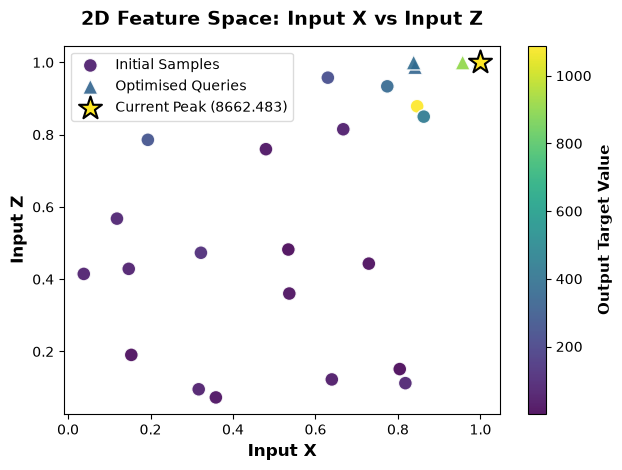

In [4]:
# ===================================
# 3.1 Visualise the data set X and Z
# ===================================

# Visualise the data set X and Z# 

# Find the coordinates of the maximum value dynamically
max_row_index = df['Output_Target'].idxmax()
max_y = df.loc[max_row_index, 'Input_X']
max_z = df.loc[max_row_index, 'Input_Z']
max_val = df.loc[max_row_index, 'Output_Target']



# Create scatter plot with the first 20 smaples
scatter1 = plt.scatter(
    data=df.iloc[:20], 
    x='Input_X', 
    y='Input_Z', 
    c='Output_Target', 
    cmap='viridis', 
    s=100,            # Marker size
    edgecolor='w',    # White border around markers
    alpha=0.9
)

# Plot the next query samples (e.g., as triangles '^')
scatter2 = plt.scatter(
    data=df.iloc[20:len(output)], 
    x='Input_X', 
    y='Input_Z', 
    c='Output_Target', 
    cmap='viridis', 
    s=120,            # Made slightly larger so triangles stand out nicely
    edgecolor='w',    
    alpha=0.9,
    marker='^',       # <--- Shape for the next 9 points
    vmin=df['Output_Target'].min(),
    vmax=df['Output_Target'].max()
)

scatter3 = plt.scatter(
    x=max_y, 
    y=max_z, 
    c=[max_val],   
    cmap='viridis',    # Highly visible contrasting color
    vmin=df['Output_Target'].min(),
    vmax=df['Output_Target'].max(),
    s=300,            # Much larger marker size to make it pop
    marker='*',       # Star shape
    edgecolor='black',
    linewidth=1.5,
    label=f'Current Max ({max_val:.2f})',
    zorder=5          # Ensures it sits on top of all other points
)


# Add elements
cbar = plt.colorbar(scatter1)
cbar.set_label('Output Target Value', fontsize=11, fontweight='bold')
plt.xlabel('Input X', fontsize=12, fontweight='bold')
plt.ylabel('Input Z', fontsize=12, fontweight='bold')
plt.title('2D Feature Space: Input X vs Input Z', fontsize=14, fontweight='bold', pad=15)

plt.legend(
    handles=[scatter1, scatter2,scatter3], 
    labels=['Initial Samples', 'Optimised Queries', f'Current Peak ({max_val:.3f})'],
    loc='upper left', 
    frameon=True, 
    facecolor='white', 
    edgecolor='lightgray', 
    fontsize=10
)
plt.tight_layout()
plt.show()

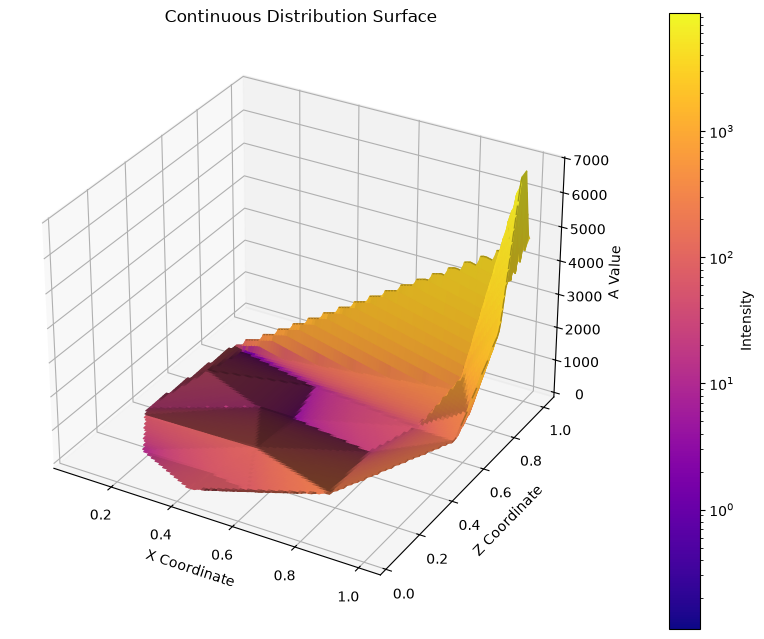

In [5]:
# ===================================
# 3.2 Visualise the data set 3D
# ===================================

coords = (inputs[:,3],inputs[:,1])

# 1. Define a regular 2D grid based on your data boundaries
grid_x, grid_y = np.meshgrid(
    np.linspace(coords[0].min(), coords[0].max(), 100),
    np.linspace(coords[1].min(), coords[1].max(), 100)
)

# 2. Interpolate the scattered (x, y, z) data onto the uniform grid
# Options for method: 'linear', 'cubic', or 'nearest'
grid_z = griddata((coords[0], coords[1]), output, (grid_x, grid_y), method='linear')

# If your y_clean variable is different from values, interpolate it too for the colors
grid_color = griddata((coords[0], coords[1]), output, (grid_x, grid_y), method='linear')

# 3. Create the 3D surface plot
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

# Plot the continuous surface
# facecolors overrides standard mapping to use your output
surf = ax.plot_surface(
    grid_x, grid_y, grid_z,
    facecolors=plt.cm.plasma(colors.LogNorm(vmin=output.min(), vmax=output.max())(grid_color)),
    rcount=100, ccount=100,  # Grid resolution
    antialiased=True,
    shade=True
)

# 4. Design elements
# Create a dummy scalar mappable object just to display the colorbar correctly
mappable = plt.cm.ScalarMappable(cmap='plasma', norm=colors.LogNorm(vmin=output.min(), vmax=output.max()))
fig.colorbar(mappable, ax=ax, label="Intensity", pad=0.1)

ax.set_xlabel("X Coordinate")
ax.set_ylabel("Z Coordinate")
ax.set_zlabel("A Value")
ax.set_title("Continuous Distribution Surface")

plt.show()

In [6]:
# ===========================================
# 4 (v1) GP Model - with UCB/EI 
# ===========================================

import numpy as np
from sklearn.ensemble import RandomForestRegressor

# Train a predictive model on your 20 existing samples
predictor = RandomForestRegressor(n_estimators=100, random_state=42)
predictor.fit(inputs, output)

def objective_4d(X):
    """
    Surrogate function for 4D optimization.
    X: A 2D numpy array of shape (n_samples, 4) sent by the optimizer.
    """
    # Force input to be 2D array matrix for sklearn compatibility
    X = np.atleast_2d(X)
    
    # Predict the output value using the trained model
    predictions = predictor.predict(X)
    
    # Return as a flat 1D array as expected by your code (.ravel())
    print(f"Prediction {predictions}")
    return predictions.ravel()

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, ConstantKernel, Matern
from scipy.stats import norm
from scipy.optimize import minimize
import warnings
warnings.filterwarnings('ignore')

def upper_confidence_bound(mu, sigma, kappa=0.1):
    """
    Upper Confidence Bound (UCB) acquisition function.
    
    UCB = mean + kappa * std
    
    Parameters:
    -----------
    mu : predicted mean
    sigma : predicted standard deviation
    kappa : exploration parameter (higher = more exploration)
    """
    return mu + kappa * sigma


def expected_improvement(mu, sigma, y_best, xi=0.05):
    """
    Expected Improvement (EI) acquisition function.
    
    EI = E[max(f(x) - f(x_best), 0)]
    
    Parameters:
    -----------
    mu : predicted mean
    sigma : predicted standard deviation  
    y_best : best observed value so far
    xi : exploration parameter
    """
    with np.errstate(divide='warn'):
        improvement = mu - y_best - xi
        Z = improvement / sigma
        ei = improvement * norm.cdf(Z) + sigma * norm.pdf(Z)
        ei[sigma == 0.0] = 0.0
    return ei

In [10]:
def bayesian_optimization_nd(objective_func, n_dims, n_iterations=5, 
                            n_initial=1, acquisition='ei'):
    """
    Bayesian Optimization for n-dimensional functions.
    Assumes bounds [0, 1] for all dimensions.
    """
    bounds = [(0, 1) for _ in range(n_dims)]
    
    # Initialize
    X_samples = inputs
    y_samples = output
    
    
    best_values = [y_samples.max()]
    
    print(f"Starting {n_dims}D optimization with {n_initial} initial samples...")
    print(f"Initial best: {y_samples.max():.4f}\n")
  
    
    for iteration in range(n_iterations):
        # Fit GP
        kernel = ConstantKernel(1.0) * Matern(length_scale=0.3,nu=1.5)
        gp = GaussianProcessRegressor(kernel=kernel, alpha=1e-6,normalize_y=True,
                                     n_restarts_optimizer=5)
        gp.fit(X_samples, y_samples)

        # Optimize acquisition function
        def acq_objective(X):
            X = X.reshape(1, -1)
            mu, sigma = gp.predict(X, return_std=True)
            
            if acquisition == 'ei':
                acq_val = expected_improvement(mu, sigma, y_samples.max())
             
            else:
                acq_val = upper_confidence_bound(mu, sigma, kappa=0.5)
            
            return -acq_val
        
        # Multi-start optimization
        best_acq = np.inf
        X_next = None


        # Build dynamic, localized acquisition optimization bounds
        # X and Y remain free (0, 1). Z is focused tightly around the 0.52 peak zone.
        localized_bounds = [
            (0.9, 1.0),  # Input_W restricted hill-climbing window
            (0.9, 1.0),  # Input_X frestricted hill-climbing window
            (0.9, 1.0),  # Input_Y free global search
            (0.9, 1.0),  # Input_Z restricted hill-climbing window
        ]

        for _ in range(25):  # More starts for higher dimensions
            # Sample initial multi-start points respecting the localized constraints
            x0 = np.array(
                [
                    np.random.uniform(localized_bounds[0][0], bounds[0][1]),
                    np.random.uniform(localized_bounds[1][0], bounds[1][1]),
                    np.random.uniform(localized_bounds[2][0], bounds[2][1]),
                    np.random.uniform(localized_bounds[3][0], bounds[3][1]),
                ])
       
            result = minimize(acq_objective, x0, bounds=localized_bounds, method='L-BFGS-B',options={"ftol": 1e-9},)
            if result.fun < best_acq:
                best_acq = result.fun
                X_next = result.x
                print(f"Optimized Next Point Found! Predicted Acquisition Score: {-best_acq:.6f}")
                print(f"Coordinates to test next: {X_next}")
            
       
        # Evaluate
        y_next = objective_func(X_next.reshape(1, -1)).ravel()
        
        # Update
        X_samples = np.vstack([X_samples, X_next])
        y_samples = np.append(y_samples, y_next)
        best_values.append(y_samples.max())
        
        if (iteration + 1) % 10 == 0:
            print(f"Iteration {iteration + 1}: Best f(x)={y_samples.max():.4f}")
    
    return X_samples, y_samples, best_values


# Run 4D optimization
X_samples_4d, y_samples_4d, best_values_4d = bayesian_optimization_nd(
    objective_4d, 
    n_dims=4,
    n_iterations=5,
    acquisition= 'ei'
)

Starting 4D optimization with 1 initial samples...
Initial best: 8662.4825

Optimized Next Point Found! Predicted Acquisition Score: 0.000000
Coordinates to test next: [0.97625023 0.95513544 0.915125   0.91720832]
Optimized Next Point Found! Predicted Acquisition Score: 24.457016
Coordinates to test next: [1.  1.  1.  0.9]
Prediction [5838.758267]
Optimized Next Point Found! Predicted Acquisition Score: 0.000000
Coordinates to test next: [0.96731421 0.92268917 0.95188284 0.90411071]
Optimized Next Point Found! Predicted Acquisition Score: 0.000000
Coordinates to test next: [0.93122894 0.90783452 0.97239692 0.94537731]
Optimized Next Point Found! Predicted Acquisition Score: 0.000000
Coordinates to test next: [0.92273933 0.91365041 0.97739949 0.9710602 ]
Optimized Next Point Found! Predicted Acquisition Score: 0.000000
Coordinates to test next: [0.92761687 0.90991871 0.94926711 0.9990435 ]
Optimized Next Point Found! Predicted Acquisition Score: 0.000000
Coordinates to test next: [0.902

In [9]:
# ============================================
# 5. Exploitation Model - scipy.optimize
# ============================================

## import numpy as np
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import Matern, ConstantKernel as C
from scipy.optimize import minimize

# 1. Load the 5D dataset (Features: W, X, Y, Z)
X_train = inputs
y_train = output

# 2. Configure a Matern GP Surrogate Model
# Matern nu=1.5 allows for the distinct "cliffs"
kernel = C(1.0, (1e-3, 1e3)) * Matern(length_scale=np.ones(4), length_scale_bounds=(1e-2, 10.0), nu=1.5)
gp = GaussianProcessRegressor(kernel=kernel, n_restarts_optimizer=25, alpha=1e-6, random_state=42)

# Fit model to historical space
gp.fit(X_train, y_train)

# 3. Formulate Optimization Target (Negative prediction for minimization algorithm)
def objective(x):
    # Predict returns shape (1, 5), flatten to extract scalar
    return -float(gp.predict(x.reshape(1, -1))[0])

# 4. Enforce Bounding Box System limits [0.0, 1.0]
bounds = [
    (0.20, 1.0),  # W
    (0.50, 1.0),  # X
    (0.65, 1.0),  # Y
    (0.01, 1.0)   # Z
]

# Use your historical peak coordinate as the optimization warm-start point
x_start = np.array([1.0, 1.0, 1.0, 1.0])

# 5. Execute L-BFGS-B Optimization Local Search
result = minimize(objective, x_start, method='L-BFGS-B', bounds=bounds)

# 6. Display Predicted Coordinates
print("--- GAUSSIAN PROCESS TARGET PREDICTION ---")
print(f"Predicted Max Output: {abs(result.fun):.4f}")
print("Optimal Coordinates:")
for name, val in zip(['W', 'X', 'Y', 'Z'], result.x):
    print(f"  Input_{name}: {val:.6f}")


--- GAUSSIAN PROCESS TARGET PREDICTION ---
Predicted Max Output: 8662.4828
Optimal Coordinates:
  Input_W: 1.000000
  Input_X: 1.000000
  Input_Y: 1.000000
  Input_Z: 0.999986
